## Import

In [1]:
import torch
from mlp_rbf_kan.models import MLP_RBFKAN, RBF_KAN, MLP, KAN, train_regression
from mlp_rbf_kan.datasets import load_heat_dataset
from mlp_rbf_kan.eval.tools import *
from mlp_rbf_kan.eval.experiments import *

## Configuration

In [2]:
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print(f"Using: {device}")

Using: cuda


In [3]:
dataset = load_heat_dataset()

Heat dataset (Parabolyc) ready!


Dataset generated:
  Training samples: 8000
  Test samples: 2000
  Input shape: torch.Size([8000, 2])
  Output shape: torch.Size([8000, 1])


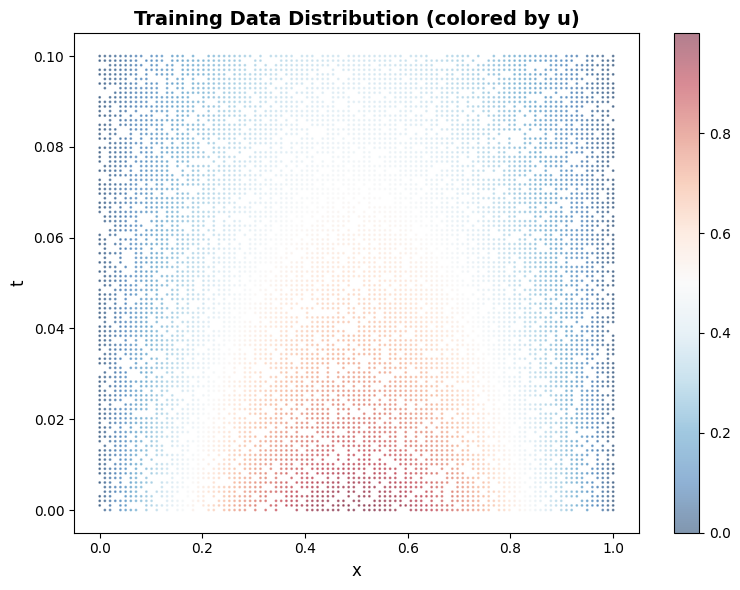

In [4]:
print(f"Dataset generated:")
print(f"  Training samples: {len(dataset['train_input'])}")
print(f"  Test samples: {len(dataset['test_input'])}")
print(f"  Input shape: {dataset['train_input'].shape}")
print(f"  Output shape: {dataset['train_label'].shape}")

# Visualize training data distribution
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
scatter = ax.scatter(dataset['train_input'][:, 0].cpu().numpy(),
                    dataset['train_input'][:, 1].cpu().numpy(),
                    c=dataset['train_label'].cpu().numpy().flatten(),
                    s=1, alpha=0.5, cmap='RdBu_r')
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('t', fontsize=12)
ax.set_title('Training Data Distribution (colored by u)', fontsize=14, fontweight='bold')
plt.colorbar(scatter, ax=ax)
plt.tight_layout()
plt.show()

In [5]:
# Hyperparameters
input_dim = 2
hidden_dim = 64
output_dim = 1
centers = 8 # or Knots
domain = (0, 1)
shared_basis = True

# Models
mlp = MLP(input_dim, hidden_dim, output_dim)
kan = KAN(width=[input_dim, hidden_dim, hidden_dim, output_dim], num_knots=centers, domain=domain) 
rbf_kan = RBF_KAN(input_dim, hidden_dim, output_dim, centers, domain)
mlp_rbf = MLP_RBFKAN(in_dim=input_dim, hidden_dim=hidden_dim, out_dim=output_dim, num_centers=centers, domain=domain, shared_basis=shared_basis)

mlp.to(device)
kan.to(device)
rbf_kan.to(device)
mlp_rbf.to(device)

MLP_RBFKAN(
  (fc1): Linear(in_features=2, out_features=64, bias=True)
  (act1): RBFKANActivation()
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (act2): RBFKANActivation()
  (fc3): Linear(in_features=64, out_features=1, bias=True)
)

## Training

In [6]:
x_train, y_train = dataset["train_input"], dataset["train_label"]
x_test, y_test = dataset["test_input"], dataset["test_label"]

In [7]:
epochs = 50
kan_learning_rate = 0.5
kan_like_optimizer = "LBFGS"
mlp_learning_rate = 0.001
mlp_like_optimizer = "adam"
batch_size = -1

# MLP
print("Training MLP...")
loss_mlp_train, loss_mlp_test, u_pred_mlp = train_regression(
    mlp, 
    x_train,
    y_train, 
    x_test, 
    y_test,
    epochs=epochs,
    lr=mlp_learning_rate,
    batch_size=batch_size,
    optimizer_type=mlp_like_optimizer,
    device=device
)

# KAN
print("\nTraining KAN...")
loss_kan_train, loss_kan_test, u_pred_kan = train_regression(
    kan, 
    x_train, 
    y_train, 
    x_test, 
    y_test,
    epochs=epochs, 
    lr=kan_learning_rate, 
    batch_size=batch_size, 
    optimizer_type=kan_like_optimizer, 
    device=device
)

# RBF-KAN
print("\nTraining RBF-KAN...")
loss_rbf_train, loss_rbf_test, u_pred_rbf = train_regression(
    rbf_kan, 
    x_train, 
    y_train, 
    x_test, 
    y_test,
    epochs=epochs, 
    lr=kan_learning_rate, 
    batch_size=batch_size,
    optimizer_type=kan_like_optimizer, 
    device=device
)

# MLP+RBF-KAN
print("\nTraining MLP+RBF-KAN...")
loss_mlp_rbf_train, loss_mlp_rbf_test, u_pred_mlp_rbf = train_regression(
    mlp_rbf, 
    x_train, 
    y_train, 
    x_test, 
    y_test,
    epochs=epochs, 
    lr=kan_learning_rate,
    batch_size=batch_size, 
    optimizer_type=kan_like_optimizer, 
    device=device
)

Training MLP...


| [Model] | train RMSE: 0.2144 | test RMSE: 0.2160 |: 100%|█████████| 50/50 [00:00<00:00, 58.42it/s]



Training KAN...


| [Model] | train RMSE: 0.0011 | test RMSE: 0.0012 |: 100%|█████████| 50/50 [00:23<00:00,  2.12it/s]



Training RBF-KAN...


| [Model] | train RMSE: 0.0016 | test RMSE: 0.0015 |: 100%|█████████| 50/50 [00:10<00:00,  4.82it/s]



Training MLP+RBF-KAN...


| [Model] | train RMSE: 0.0015 | test RMSE: 0.0016 |: 100%|█████████| 50/50 [00:12<00:00,  4.13it/s]


## Results

In [8]:
x_test = dataset['test_input'].to(device)
y_test = dataset['test_label'].to(device)

mlp.to(device)
kan.to(device)
rbf_kan.to(device)
mlp_rbf.to(device)

# Inference
u_pred_mlp_test = mlp(x_test).detach().cpu()
u_pred_kan_test = kan(x_test).detach().cpu()
u_pred_rbf_test = rbf_kan(x_test).detach().cpu()
u_pred_mlp_rbf_test = mlp_rbf(x_test).detach().cpu()

# MLP Metrics
print("MLP: metrics (test)")
metrics = compute_all_metrics(u_pred_mlp_test, y_test.cpu())
for k, v in metrics.items():
    print(f"{k}: {v:.6f}")

# KAN Metrics
print("\nKAN: metrics (test)")
metrics = compute_all_metrics(u_pred_kan_test, y_test.cpu())
for k, v in metrics.items():
    print(f"{k}: {v:.6f}")

# RBF-KAN Metrics
print("\nRBF-KAN: metrics (test)")
metrics = compute_all_metrics(u_pred_rbf_test, y_test.cpu())
for k, v in metrics.items():
    print(f"{k}: {v:.6f}")

# MLP with RBF-KAN metrics
print("\nMLP+RBF-KAN: metrics (test)")
metrics = compute_all_metrics(u_pred_mlp_rbf_test, y_test.cpu())
for k, v in metrics.items():
    print(f"{k}: {v:.6f}")

MLP: metrics (test)
relative_L2: 0.464700
L_inf: 0.584113
RMSE: 0.216041
MSE: 0.046674

KAN: metrics (test)
relative_L2: 0.002670
L_inf: 0.007567
RMSE: 0.001241
MSE: 0.000002

RBF-KAN: metrics (test)
relative_L2: 0.003235
L_inf: 0.010605
RMSE: 0.001504
MSE: 0.000002

MLP+RBF-KAN: metrics (test)
relative_L2: 0.003354
L_inf: 0.007836
RMSE: 0.001559
MSE: 0.000002


In [9]:
print(f"Number of paramters [MLP]: {n_parameters(mlp)}")
print(f"Number of paramters [KAN]: {n_parameters(kan)}")
print(f"Number of paramters [RBF-KAN]: {n_parameters(rbf_kan)}")
print(f"Number of paramters [MLP with RBF-KAN]: {n_parameters(mlp_rbf)}")

Number of paramters [MLP]: 4417
Number of paramters [KAN]: 51456
Number of paramters [RBF-KAN]: 34481
Number of paramters [MLP with RBF-KAN]: 5729


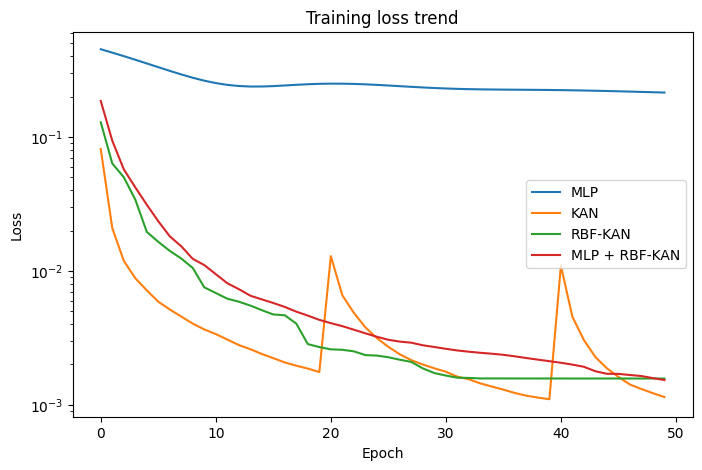

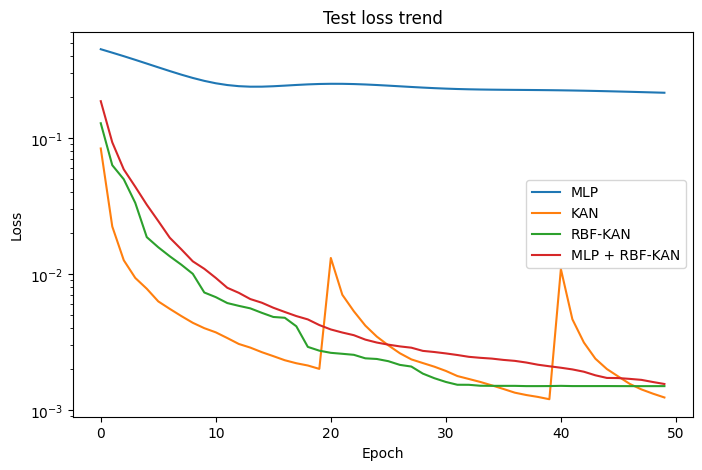

MLP Final Loss: 0.21604087948799133
KAN Final Loss: 0.0012412278447300196
RBF-KAN Final Loss: 0.0015041700098663568
MLP with RBF-KAN Final Loss: 0.001559385214932263


In [10]:
plot_losses({
    "MLP": loss_mlp_train,
    "KAN": loss_kan_train,
    "RBF-KAN": loss_rbf_train,
    "MLP + RBF-KAN": loss_mlp_rbf_train,
}, "Training loss trend")

plot_losses({
    "MLP": loss_mlp_test,
    "KAN": loss_kan_test,
    "RBF-KAN": loss_rbf_test,
    "MLP + RBF-KAN": loss_mlp_rbf_test,
}, "Test loss trend")

print(f"MLP Final Loss: {loss_mlp_test[-1]}")
print(f"KAN Final Loss: {loss_kan_test[-1]}")
print(f"RBF-KAN Final Loss: {loss_rbf_test[-1]}")
print(f"MLP with RBF-KAN Final Loss: {loss_mlp_rbf_test[-1]}")

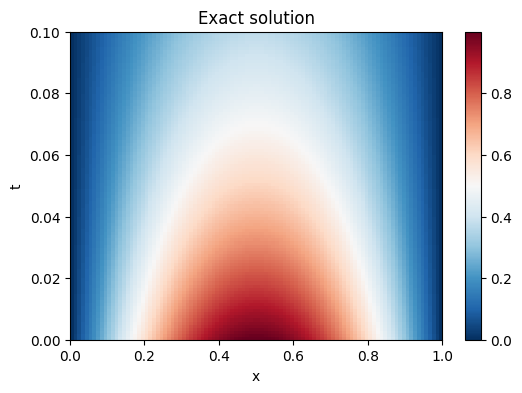

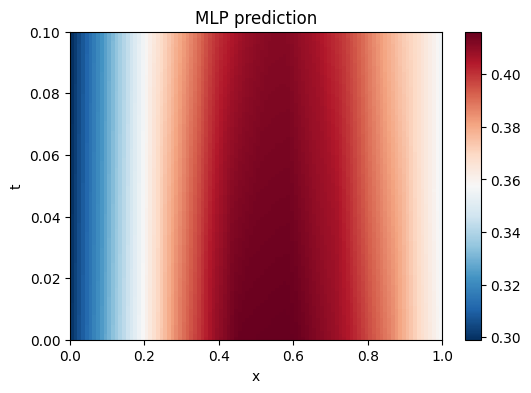

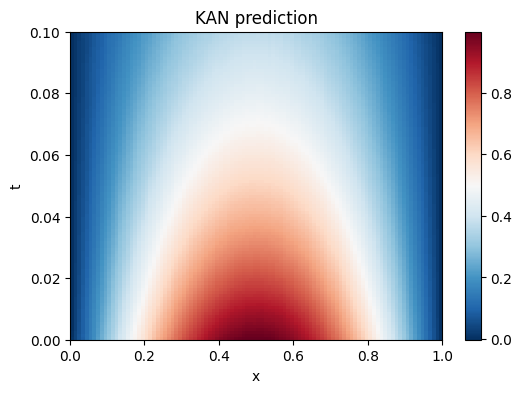

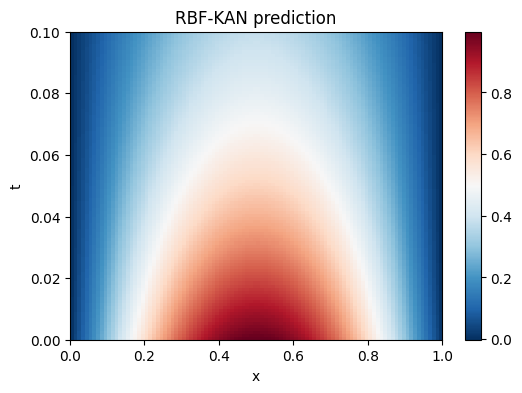

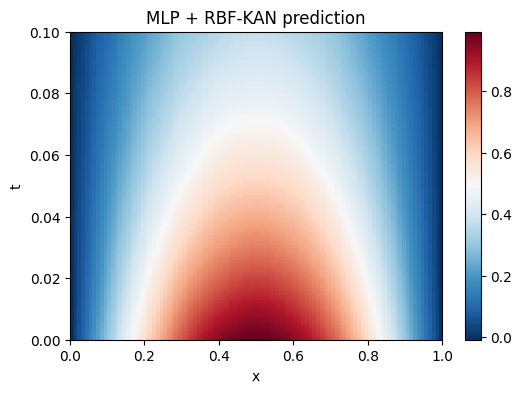

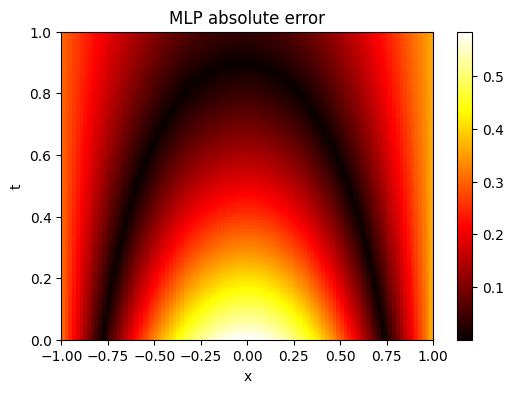

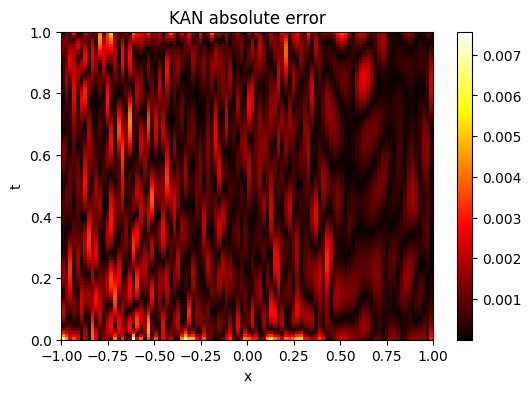

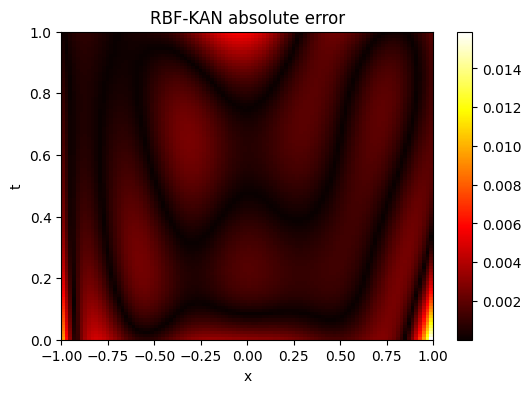

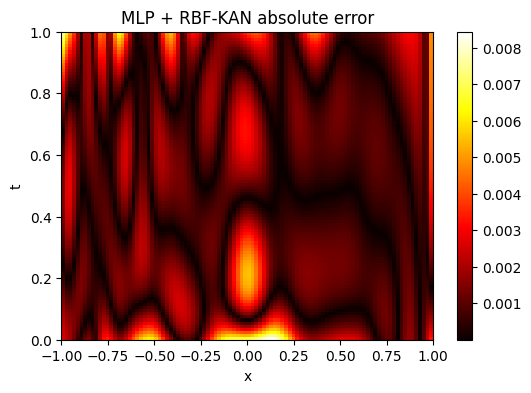

In [11]:
X_plot = dataset['X_test']
T_plot = dataset['T_test']
grid_input_np = np.stack([X_plot.ravel(), T_plot.ravel()], axis=-1)
grid_input = torch.tensor(grid_input_np, dtype=torch.float32).to(device)

with torch.no_grad():
    u_pred_mlp_full = mlp(grid_input).cpu()
    u_pred_kan_full = kan(grid_input).cpu()
    u_pred_rbf_full = rbf_kan(grid_input).cpu()
    u_pred_ibrido_full = mlp_rbf(grid_input).cpu()

U_exact_grid = (np.sin(np.pi * X_plot) * np.exp(-(np.pi**2) * T_plot))

u_mlp_grid = u_pred_mlp_full.numpy().reshape(dataset['nt_test'], dataset['nx_test'])
u_kan_grid = u_pred_kan_full.numpy().reshape(dataset['nt_test'], dataset['nx_test'])
u_rbf_grid = u_pred_rbf_full.numpy().reshape(dataset['nt_test'], dataset['nx_test'])
u_ibrido_grid = u_pred_ibrido_full.numpy().reshape(dataset['nt_test'], dataset['nx_test'])

# Solutions
plot_eq_solution(U_exact_grid, "Exact solution", dataset["nx_test"], dataset["nt_test"], (0,1), (0,0.1))
plot_eq_solution(u_mlp_grid, "MLP prediction", dataset["nx_test"], dataset["nt_test"], (0,1), (0,0.1))
plot_eq_solution(u_kan_grid, "KAN prediction", dataset["nx_test"], dataset["nt_test"], (0,1), (0,0.1))
plot_eq_solution(u_rbf_grid, "RBF-KAN prediction", dataset["nx_test"], dataset["nt_test"], (0,1), (0,0.1))
plot_eq_solution(u_ibrido_grid, "MLP + RBF-KAN prediction", dataset["nx_test"], dataset["nt_test"], (0,1), (0,0.1))

# Errors
U_exact_tensor = torch.tensor(U_exact_grid)
plot_error(torch.tensor(u_mlp_grid), U_exact_tensor, "MLP absolute error", dataset["nx_test"], dataset["nt_test"])
plot_error(torch.tensor(u_kan_grid), U_exact_tensor, "KAN absolute error", dataset["nx_test"], dataset["nt_test"])
plot_error(torch.tensor(u_rbf_grid), U_exact_tensor, "RBF-KAN absolute error", dataset["nx_test"], dataset["nt_test"])
plot_error(torch.tensor(u_ibrido_grid), U_exact_tensor, "MLP + RBF-KAN absolute error", dataset["nx_test"], dataset["nt_test"])

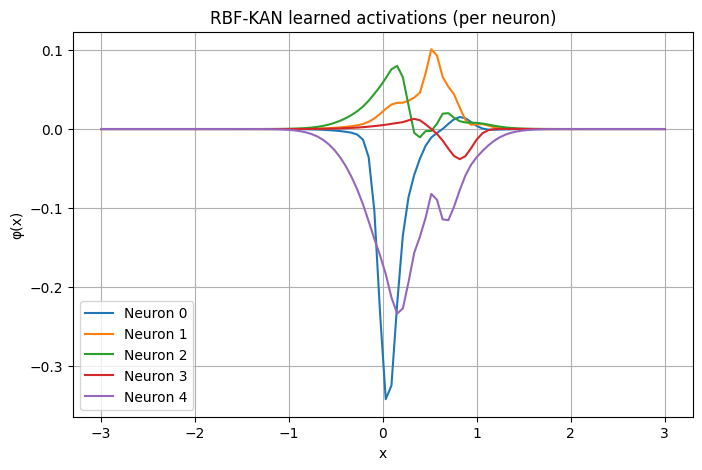

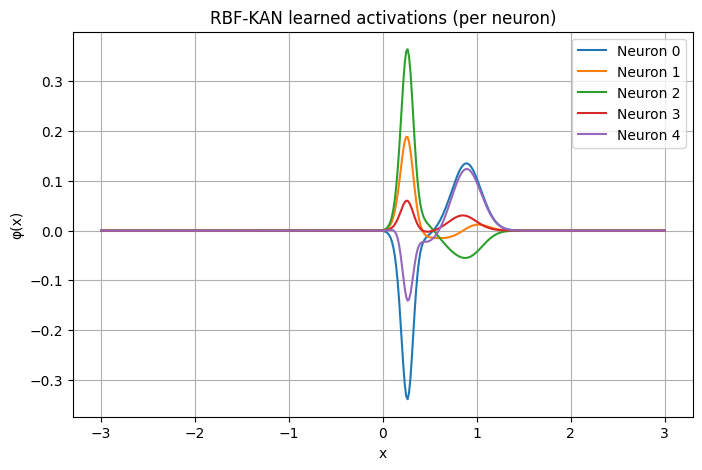

In [ ]:
plot_rbf_neurons(mlp_rbf.act1)
plot_rbf_neurons(mlp_rbf.act2)

## Model comparison: Heat Equation

In [ ]:
# Models definition
models = {
    "MLP": lambda: MLP(input_dim, hidden_dim, output_dim),
    "KAN": lambda: KAN(
        width=[input_dim, hidden_dim, hidden_dim, output_dim],
        num_knots=centers,
        domain=domain
    ),
    "RBF-KAN": lambda: RBF_KAN(
        input_dim, hidden_dim, output_dim, centers, domain
    ),
    "MLP with RBF-KAN": lambda: MLP_RBFKAN(
        in_dim=input_dim,
        hidden_dim=hidden_dim,
        out_dim=output_dim,
        num_centers=centers,
        domain=domain,
        shared_basis=shared_basis
    )
}

In [ ]:
# Dataset
dataset = load_heat_dataset()

# Experiment
cfg = ExperimentCfg(
        models = models,
        seeds = [2,23,54,2,45],
        input_dim = 2,
        hidden_dim = 64,
        output_dim = 1,
        centers = 8,
        domain = (0, 1),
        shared_basis = True,
        epochs = 50,
        mlp_lr = 1e-3,
        kan_lr = 0.5,
        batch_size = -1,
        mlp_optimizer = "adam",
        kan_optimizer = "lbfgs",
        device = "cuda",
        dataset = dataset
    )

runner = ExperimentalRunner(cfg)
runner.run_battery_experiments_regression()
runner.plot_metrics_summary()